# trunk_shred_nektar

**Question.** Does the DeepONet-style trunk SHRED (prototyped on the 1D wave, `notebooks/trunk_shred_wave.ipynb`)
train on the Nektar cylinder wake (u, v), and what does a continuity loss ∇·u = 0 change?

**Setup.** `configs/experiment/trunk_shred_nektar.yaml`, Nektar u, v (100 × 50 grid, x ∈ [1, 8], y ∈ [−2, 2],
200 snapshots, dt = 0.1), N = 8 probes, lags = 10, clean training and evaluation. Status: **prototype, seed 0 only so far.**

## The model (`FlowTrunkSHRED`, `src/get_shredded/model.py`)

* **Branch.** SHRED's GRU over the probe window → 2 × p coefficients (one set for u, one for v).
* **Trunk.** tanh MLP over Fourier features sin/cos(kπz), k = 1..n, of (x, y) scaled to [0, 1] per axis
  → p basis functions per channel. u_c(x, y) = b_c · T_c(x, y) + bias_c, in physical units.
* **No time input** (user's choice): only the last frame is supervised, so τ was unused on the wave.
  This rules out NS momentum (needs u_t); the only physics term is continuity.
* **Physics.** λ × mean (u_x + v_y)² on 64 random (x, y) points per sample in the grid's box (the cylinder lies outside it).
* Output is MinMax-scaled like SHRED's, so target, loss and metrics equal SHRED's.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from IPython.display import Markdown, display
from get_shredded.runner import load_arrays, load_config, load_results, output_root

def root(name, extra=()):
    return output_root(load_config(["+experiment=trunk_shred_nektar", f"name={name}", *extra]))

MAIN = root("trunk_shred_nektar")              # the experiment itself (seed 0 so far)
SMOKE20 = root("trunk_shred_nektar_smoke")     # 20 epochs, all 5 original runs
SMOKE200 = root("trunk_shred_nektar_smoke200") # 200 epochs, shred + plain trunk
LONG = root("trunk_shred_nektar_long")         # 5000 epochs, early stopping off
cfg = load_config(["+experiment=trunk_shred_nektar"])
FLOOR = 0.328                                  # test error of predicting the mean field

def table(rt, seed=0):
    res = load_results(rt)
    rows = ["| run | width | p | freq. | λ | test err | train err | val checks (≈ epochs) | params |",
            "|---|---:|---:|---:|---:|---:|---:|---:|---:|"]
    for (r, s), x in sorted(res.items(), key=lambda kv: kv[1]["metrics"]["clean"]["err"]):
        if s != seed:
            continue
        m, met = cfg.methods[r.split("__")[0]], x["metrics"]
        rows.append(f"| {r} | {m.get('trunk_width', '–')} | {m.get('p', '–')} | {m.get('num_frequencies', '–')} "
                    f"| {m.get('physics_weight', '–')} | {met['clean']['err']:.4f} | {met['train']['err']:.4f} "
                    f"| {met['epochs_used']} (≈ {20 * (met['epochs_used'] - 1)}) | {met['parameters']:,} |")
    return Markdown("\n".join(rows)) if len(rows) > 2 else Markdown("_not run yet_")

## 1. Smoke runs (seed 0)

Validation is checked at epoch 1 and every 20 epochs; *val checks* counts those, so 11 checks ≈ 200 epochs.
Mean-field floor: 0.328.

**20 epochs**, all original runs:

In [2]:
display(table(SMOKE20))

| run | width | p | freq. | λ | test err | train err | val checks (≈ epochs) | params |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| shred__clean | – | – | – | – | 0.0924 | 0.0933 | 2 (≈ 20) | 4,213,854 |
| flow_trunk_shred__clean | 64 | 64 | 16 | 0.0 | 0.3317 | 0.3317 | 2 (≈ 20) | 65,666 |
| flow_trunk_shred_div_weak__clean | 256 | 128 | 16 | 0.0001 | 0.3317 | 0.3317 | 2 (≈ 20) | 65,666 |
| flow_trunk_shred_div__clean | 256 | 128 | 16 | 0.001 | 0.3317 | 0.3318 | 2 (≈ 20) | 65,666 |
| flow_trunk_shred_div_strong__clean | 256 | 128 | 16 | 0.01 | 0.3323 | 0.3324 | 2 (≈ 20) | 65,666 |

**200 epochs**, SHRED and the plain trunk:

In [3]:
display(table(SMOKE200))

| run | width | p | freq. | λ | test err | train err | val checks (≈ epochs) | params |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| shred__clean | – | – | – | – | 0.0050 | 0.0050 | 11 (≈ 200) | 4,213,854 |
| flow_trunk_shred__clean | 64 | 64 | 16 | 0.0 | 0.1987 | 0.2010 | 11 (≈ 200) | 65,666 |

After 20 epochs every trunk run sits at the mean-field floor, so the continuity weights cannot be compared yet.
After 200 epochs neither run has stopped early; the trunk is at 0.20 against SHRED's 0.005.

## 2. The data's own divergence (floor for any continuity result)

Second-order finite differences on the grid. The data is interpolated from a spectral-element solution, so it is
not exactly divergence-free.

In [4]:
d = loadmat("../data/cylinder_nektar_wake.mat")
X, U = d["X_star"], d["U_star"]
xs, ys = np.unique(X[:, 0]), np.unique(X[:, 1])
u = U[:, 0, :].reshape(len(xs), len(ys), -1, order="F")
v = U[:, 1, :].reshape(len(xs), len(ys), -1, order="F")
ux, uy = np.gradient(u, xs, axis=0, edge_order=2), np.gradient(u, ys, axis=1, edge_order=2)
vx, vy = np.gradient(v, xs, axis=0, edge_order=2), np.gradient(v, ys, axis=1, edge_order=2)
div_rms = np.sqrt(((ux + vy) ** 2).mean())
grad_rms = np.sqrt((ux**2 + uy**2 + vx**2 + vy**2).mean())
print(f"rms(u_x + v_y) = {div_rms:.4f}, relative to rms(|grad u|): {div_rms / grad_rms:.4f}")

rms(u_x + v_y) = 0.0026, relative to rms(|grad u|): 0.0034


## 3. Trunk search at 1000 epochs (seed 0, default early stopping)

Plain trunk (width 64, p = 64, 16 frequencies) against a wider trunk with p = 128, and 32 instead of 16 frequencies.
These are the experiment's own runs (`outputs/trunk_shred_nektar`), so the 3-seed run reuses them.

In [5]:
display(table(MAIN))

| run | width | p | freq. | λ | test err | train err | val checks (≈ epochs) | params |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| shred__clean | – | – | – | – | 0.0027 | 0.0026 | 25 (≈ 480) | 4,213,854 |
| flow_trunk_shred_div_strong__clean | 256 | 128 | 16 | 0.01 | 0.0367 | 0.0367 | 51 (≈ 1000) | 205,570 |
| flow_trunk_shred_div__clean | 256 | 128 | 16 | 0.001 | 0.0371 | 0.0372 | 51 (≈ 1000) | 205,570 |
| flow_trunk_shred_w256_cos_lr3__clean | 256 | 128 | 16 | 0.0 | 0.0371 | 0.0373 | 51 (≈ 1000) | 205,570 |
| flow_trunk_shred_div_weak__clean | 256 | 128 | 16 | 0.0001 | 0.0372 | 0.0373 | 51 (≈ 1000) | 205,570 |
| flow_trunk_shred_w256__clean | 256 | 128 | 16 | 0.0 | 0.0436 | 0.0438 | 37 (≈ 720) | 205,570 |
| flow_trunk_shred_w256_ff32__clean | 256 | 128 | 32 | 0.0 | 0.0443 | 0.0446 | 44 (≈ 860) | 221,954 |
| flow_trunk_shred_w256_cos__clean | 256 | 128 | 16 | 0.0 | 0.0446 | 0.0448 | 51 (≈ 1000) | 205,570 |
| flow_trunk_shred_w128__clean | 128 | 128 | 16 | 0.0 | 0.0483 | 0.0488 | 45 (≈ 880) | 115,202 |
| flow_trunk_shred__clean | 64 | 64 | 16 | 0.0 | 0.0528 | 0.0534 | 51 (≈ 1000) | 65,666 |
| flow_trunk_shred_ff32__clean | 64 | 64 | 32 | 0.0 | 0.0659 | 0.0657 | 51 (≈ 1000) | 69,762 |
| flow_trunk_shred_cos__clean | 64 | 64 | 16 | 0.0 | 0.0786 | 0.0793 | 51 (≈ 1000) | 65,666 |

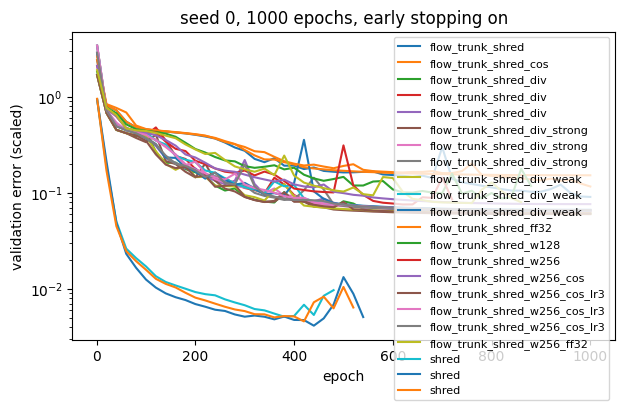

In [6]:
def curves(rt, runs=None, title=""):
    res = load_results(rt)
    fig, ax = plt.subplots(figsize=(7, 4))
    for (r, s) in sorted(res):
        if runs is not None and r not in runs:
            continue
        h = load_arrays(rt, r, s)["val_history"]
        epochs = np.r_[1, 20 * np.arange(1, len(h))]
        ax.semilogy(epochs, h, label=r.replace("__clean", ""))
    ax.set(xlabel="epoch", ylabel="validation error (scaled)", title=title)
    ax.legend(fontsize=8)
    plt.show()

curves(MAIN, title="seed 0, 1000 epochs, early stopping on")

Result (seed 0): SHRED 0.0027 (stopped at ≈ 480 epochs); best trunk 0.044 (width 256, p = 128), about 16× worse.
Size helps little (0.053 → 0.044), 32 frequencies hurt at the base size (0.066) and change nothing at width 256.
Train error equals test error in every trunk run: the trunk underfits, it does not overfit.

## 4. Why does the trunk underfit? Hypothesis: it trains much slower

The user's hypothesis, a known result for DeepONet-style models: the coordinate MLP learns coarse spatial patterns first
and fine ones slowly (spectral bias). Test: 5000 epochs with early stopping off (`name=trunk_shred_nektar_long`) for SHRED,
the plain trunk and the width-256 trunk. If the hypothesis holds, the trunk's validation error keeps falling well past
1000 epochs while SHRED's levels off early.

In [7]:
display(table(LONG))

| run | width | p | freq. | λ | test err | train err | val checks (≈ epochs) | params |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| shred__clean__nostop | – | – | – | – | 0.0019 | 0.0018 | 251 (≈ 5000) | 4,213,854 |
| flow_trunk_shred_w256__clean__nostop | 256 | 128 | 16 | 0.0 | 0.0109 | 0.0117 | 251 (≈ 5000) | 205,570 |
| flow_trunk_shred__clean__nostop | 64 | 64 | 16 | 0.0 | 0.0158 | 0.0157 | 251 (≈ 5000) | 65,666 |

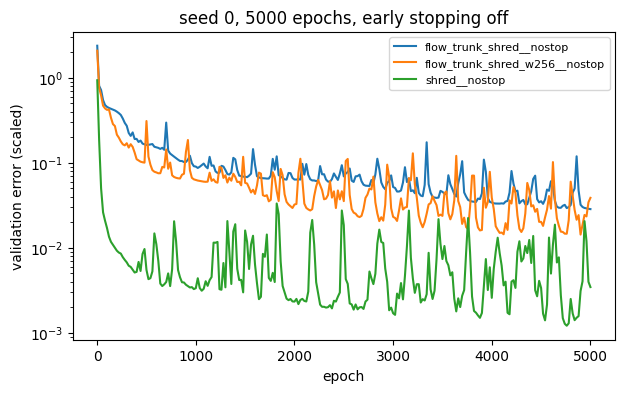

In [8]:
if load_results(LONG):
    curves(LONG, title="seed 0, 5000 epochs, early stopping off")

In [9]:
for (r, s), x in sorted(load_results(LONG).items()):
    h = load_arrays(LONG, r, s)["val_history"]
    e = np.r_[1, 20 * np.arange(1, len(h))]
    at = {k: float(h[np.searchsorted(e, k)]) for k in (1000, 2000, 3000, 4000)}
    print(f"{r:40s} test {x['metrics']['clean']['err']:.4f}  best val {h.min():.4f} at epoch {e[h.argmin()]}  "
          + "  ".join(f"val@{k} {v:.4f}" for k, v in at.items()))

flow_trunk_shred__clean__nostop          test 0.0158  best val 0.0285 at epoch 5000  val@1000 0.0903  val@2000 0.0636  val@3000 0.0520  val@4000 0.0341
flow_trunk_shred_w256__clean__nostop     test 0.0109  best val 0.0143 at epoch 4900  val@1000 0.0628  val@2000 0.0323  val@3000 0.0231  val@4000 0.0390
shred__clean__nostop                     test 0.0019  best val 0.0012 at epoch 4760  val@1000 0.0034  val@2000 0.0023  val@3000 0.0017  val@4000 0.0026


**Result (seed 0, 5000 epochs, no early stopping).** Test error: SHRED 0.0019 (vs 0.0027 at default training),
plain trunk 0.0158 (vs 0.053), width-256 trunk 0.0109 (vs 0.044). The gap to SHRED shrinks from about 16× to about 6×
(width 256) and 8× (plain). Train error still equals test error.

**Conclusion (tentative, one seed).** The hypothesis holds: the trunk mostly underfits because it trains slowly, not
because it is too small. Its best validation error is still at the last checks (epoch 4900–5000), so it has not
converged at 5000 epochs. SHRED keeps improving too (best validation 0.0012 at epoch 4760), but it is far ahead from the
start: it is at 0.009 after 200 epochs, a level the width-256 trunk does not reach in 5000. Early stopping is a minor factor: patience counts checks without a *new best* (5 checks = 100 epochs), so a spike
only matters if the curve then fails to beat its old best within 100 epochs. Width 256 stopped at epoch 720 two checks
before its next best (0.0713 at 760 vs 0.0754); val at 1000 would have been 0.063. The plain trunk ran the full 1000
epochs. The main limit is the 1000-epoch budget, not early stopping. Note: without early stopping `fit` keeps the
last-epoch model (no best-checkpoint restore), so the 5000-epoch test errors are last-epoch errors.
Capacity still matters a little (width 256 beats 64 at every point after 1000 epochs).

## 5. Cosine learning-rate decay (seed 0, standard protocol)

`lr_schedule: cosine` decays lr from 1e-3 to 0 over the 1000 epochs (`torch.optim.lr_scheduler.CosineAnnealingLR`,
stepped per epoch), default early stopping. `_cos_lr3` starts from 3e-3 (per-method `lr` override). Target: the late validation spikes and the slow convergence. Off by
default; no other method changes. Rows `*_cos` in the table of section 3; curves against the fixed-lr runs:

| run | width | p | freq. | λ | test err | train err | val checks (≈ epochs) | params |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| shred__clean | – | – | – | – | 0.0027 | 0.0026 | 25 (≈ 480) | 4,213,854 |
| flow_trunk_shred_div_strong__clean | 256 | 128 | 16 | 0.01 | 0.0367 | 0.0367 | 51 (≈ 1000) | 205,570 |
| flow_trunk_shred_div__clean | 256 | 128 | 16 | 0.001 | 0.0371 | 0.0372 | 51 (≈ 1000) | 205,570 |
| flow_trunk_shred_w256_cos_lr3__clean | 256 | 128 | 16 | 0.0 | 0.0371 | 0.0373 | 51 (≈ 1000) | 205,570 |
| flow_trunk_shred_div_weak__clean | 256 | 128 | 16 | 0.0001 | 0.0372 | 0.0373 | 51 (≈ 1000) | 205,570 |
| flow_trunk_shred_w256__clean | 256 | 128 | 16 | 0.0 | 0.0436 | 0.0438 | 37 (≈ 720) | 205,570 |
| flow_trunk_shred_w256_ff32__clean | 256 | 128 | 32 | 0.0 | 0.0443 | 0.0446 | 44 (≈ 860) | 221,954 |
| flow_trunk_shred_w256_cos__clean | 256 | 128 | 16 | 0.0 | 0.0446 | 0.0448 | 51 (≈ 1000) | 205,570 |
| flow_trunk_shred_w128__clean | 128 | 128 | 16 | 0.0 | 0.0483 | 0.0488 | 45 (≈ 880) | 115,202 |
| flow_trunk_shred__clean | 64 | 64 | 16 | 0.0 | 0.0528 | 0.0534 | 51 (≈ 1000) | 65,666 |
| flow_trunk_shred_ff32__clean | 64 | 64 | 32 | 0.0 | 0.0659 | 0.0657 | 51 (≈ 1000) | 69,762 |
| flow_trunk_shred_cos__clean | 64 | 64 | 16 | 0.0 | 0.0786 | 0.0793 | 51 (≈ 1000) | 65,666 |

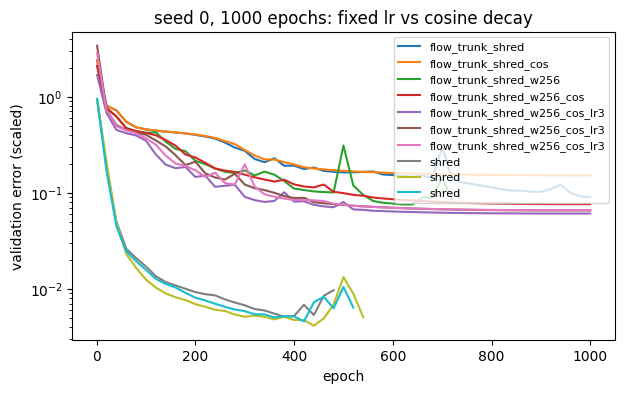

In [10]:
COS = ["flow_trunk_shred__clean", "flow_trunk_shred_cos__clean", "flow_trunk_shred_w256__clean",
       "flow_trunk_shred_w256_cos__clean", "flow_trunk_shred_w256_cos_lr3__clean", "shred__clean"]
display(table(MAIN))
curves(MAIN, runs=COS, title="seed 0, 1000 epochs: fixed lr vs cosine decay")

**Result (seed 0, 1000 epochs).** Test error: plain trunk 0.053 (fixed 1e-3) → 0.079 (cosine from 1e-3);
width 256: 0.044 (fixed 1e-3) → 0.045 (cosine from 1e-3) → **0.037** (cosine from 3e-3). All cosine runs use the full
1000 epochs (no early stop) and have their best validation at the last check, so they are still improving.

**Conclusion (tentative, one seed).** Decay alone removes the spikes but lowers the average step size, which slows an
already slow model (plain trunk worse). A higher start with decay helps (0.044 → 0.037, ahead of fixed lr at every
check: val 0.146 vs 0.215 at epoch 200), but only modestly: the trunk is still ≈ 14× behind SHRED (0.0027) at
1000 epochs, against ≈ 6× at 5000 epochs with fixed lr (section 4). The training length dominates; the schedule is
a second-order gain.

## 6. Full runs, 3 seeds

Trunk = width 256, p = 128, 16 frequencies, cosine lr from 3e-3; `*_div*` add continuity with λ = 1e-4 / 1e-3 / 1e-2.
**A**: standard protocol (`trunk_shred_nektar`, 1000 epochs, early stopping). **B**: `trunk_shred_nektar_5k`
(5000-epoch budget, early stopping), plus the trunk with fixed lr 1e-3.

In [11]:
FIVEK = root("trunk_shred_nektar_5k")

def seeds_table(name, rt):
    res = load_results(rt)
    runs = [f"{r.method}__{r.train}" for r in load_config([f"+experiment={name}"]).runs]
    rows = ["| run | λ | test err | per seed | train err | val checks per seed (≈ epochs = 20 × (checks − 1)) |",
            "|---|---:|---:|---|---:|---|"]
    for r in runs:
        xs = [res[(r, s)]["metrics"] for s in (0, 1, 2) if (r, s) in res]
        te = np.array([m["clean"]["err"] for m in xs])
        rows.append(f"| {r} | {cfg.methods[r.split('__')[0]].get('physics_weight', '–')} "
                    f"| {te.mean():.4f} ± {te.std():.4f} | {' / '.join(f'{v:.4f}' for v in te)} "
                    f"| {np.mean([m['train']['err'] for m in xs]):.4f} | {[m['epochs_used'] for m in xs]} |")
    return Markdown("\n".join(rows))

display(Markdown("**A: standard protocol**"), seeds_table("trunk_shred_nektar", MAIN))
display(Markdown("**B: 5000-epoch budget, early stopping**"), seeds_table("trunk_shred_nektar_5k", FIVEK))

**A: standard protocol**

| run | λ | test err | per seed | train err | val checks per seed (≈ epochs = 20 × (checks − 1)) |
|---|---:|---:|---|---:|---|
| shred__clean | – | 0.0026 ± 0.0002 | 0.0027 / 0.0028 / 0.0024 | 0.0023 | [25, 28, 27] |
| flow_trunk_shred_w256_cos_lr3__clean | 0.0 | 0.0400 ± 0.0021 | 0.0371 / 0.0421 / 0.0407 | 0.0390 | [51, 51, 51] |
| flow_trunk_shred_div_weak__clean | 0.0001 | 0.0401 ± 0.0022 | 0.0372 / 0.0422 / 0.0410 | 0.0392 | [51, 51, 51] |
| flow_trunk_shred_div__clean | 0.001 | 0.0398 ± 0.0021 | 0.0371 / 0.0420 / 0.0405 | 0.0389 | [51, 51, 51] |
| flow_trunk_shred_div_strong__clean | 0.01 | 0.0392 ± 0.0018 | 0.0367 / 0.0409 / 0.0399 | 0.0382 | [51, 51, 51] |

**B: 5000-epoch budget, early stopping**

| run | λ | test err | per seed | train err | val checks per seed (≈ epochs = 20 × (checks − 1)) |
|---|---:|---:|---|---:|---|
| shred__clean | – | 0.0026 ± 0.0002 | 0.0027 / 0.0028 / 0.0024 | 0.0023 | [25, 28, 27] |
| flow_trunk_shred_w256__clean | 0.0 | 0.0530 ± 0.0136 | 0.0436 / 0.0431 / 0.0721 | 0.0519 | [37, 45, 23] |
| flow_trunk_shred_w256_cos_lr3__clean | 0.0 | 0.0481 ± 0.0048 | 0.0431 / 0.0466 / 0.0546 | 0.0471 | [26, 29, 23] |
| flow_trunk_shred_div_weak__clean | 0.0001 | 0.0417 ± 0.0011 | 0.0422 / 0.0402 / 0.0427 | 0.0408 | [27, 43, 32] |
| flow_trunk_shred_div__clean | 0.001 | 0.0442 ± 0.0027 | 0.0473 / 0.0445 / 0.0408 | 0.0432 | [23, 31, 37] |
| flow_trunk_shred_div_strong__clean | 0.01 | 0.0403 ± 0.0005 | 0.0407 / 0.0397 / 0.0405 | 0.0393 | [28, 42, 34] |

**Result.** A: SHRED 0.0026 ± 0.0002; trunk 0.0400 ± 0.0021; with continuity 0.0401 / 0.0398 / 0.0392 for
λ = 1e-4 / 1e-3 / 1e-2, all within the seed spread (per seed the differences are ≤ 0.001). Every trunk run uses the full
1000 epochs. B: early stopping ends every run after 23–45 checks (≈ 440–880 epochs), so the 5000-epoch budget is never
used. SHRED stops at the same epoch as in A and gives the same numbers. The cosine trunk is *worse* than in A
(0.048 vs 0.040): its lr decays over 5000 epochs, so it is still near 3e-3 when early stopping ends the run.

**Conclusion (tentative).** Regime B as configured does not test long training: with early stopping on, the trunk's
validation spikes end every run before 1000 epochs. The 5000-epoch diagnostic (section 4, no early stopping) is the
only long-training evidence. Continuity has no measurable effect on the undertrained trunk (A).